In [1]:
%pip install pvlib scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


# AI for building energy: forecasting solar and demand to run a battery smarter
**Author:** Maduakor Uchechukwu David · MSc Energy for Solar Buildings and Cities

**Business question:** a commercial building in Grenoble has a 400 kWp rooftop PV plant and a 300 kWh battery. Can machine-learning (ML) forecasts of tomorrow's solar output and building demand reduce its electricity bill, compared with simple rules?

| # | Step | Method |
|---|---|---|
| 1 | Data | 2 years of hourly PVGIS weather, PV output with `pvlib`, office demand model |
| 2 | Forecasting | Day-ahead forecasts: persistence baseline vs gradient-boosted trees (`scikit-learn`) |
| 3 | Explainability | Permutation importance: which inputs drive each forecast |
| 4 | Battery control | Same battery, five control strategies |
| 5 | Business case | Annual cost, self-consumption, self-sufficiency, CO₂ |

Year 1 (2019) trains the models. Year 2 (2020) is kept unseen for testing, which is how a forecast is judged in a real deployment.

In [2]:
##libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error

RNG = np.random.default_rng(7)     

## 1. Data
### 1.1 Site, PV system and weather
Grenoble (45.19 N, 5.72 E). Rooftop PV: **400 kWp**, 15° tilt facing south, 330 kW of inverters.
Hourly **in-plane irradiance**, air temperature and wind speed for **2019–2020** come from the PVGIS API (SARAH satellite data).
Unlike the TMY used in notebook 1, these are **real consecutive years**, which a forecast needs.

In [3]:
#A: site settings

SITE = dict(name="Grenoble, France", lat=45.19, lon=5.72, tz="Europe/Paris")
PV_KWP, INV_KW, TILT, AZIMUTH = 400, 330, 15, 180
YEARS = (2019, 2020)
location = pvlib.location.Location(SITE["lat"], SITE["lon"], tz="UTC", altitude=212)

In [4]:
#B: download two real years from PVGIS

raw, *_ = pvlib.iotools.get_pvgis_hourly(
    SITE["lat"], SITE["lon"], start=YEARS[0], end=YEARS[1],
    surface_tilt=TILT, surface_azimuth=AZIMUTH, components=True,
    map_variables=True, timeout=60)

weather = pd.DataFrame({
    "poa_global": raw[["poa_direct", "poa_sky_diffuse", "poa_ground_diffuse"]].sum(axis=1),
    "temp_air":   raw["temp_air"],
    "wind_speed": raw["wind_speed"]})
weather.index = weather.index.floor("h") + pd.Timedelta("30min")

print(f"{len(weather):,} hours from {weather.index[0]} to {weather.index[-1]}")
weather.describe().round(1)

17,544 hours from 2019-01-01 00:30:00+00:00 to 2020-12-31 23:30:00+00:00


,poa_global,temp_air,wind_speed
count,17544.0,17544.0,17544.0
mean,186.2,9.0,1.1
std,286.8,8.3,0.5
min,0.0,-11.5,0.0
25%,0.0,2.5,0.7
50%,0.0,8.6,1.0
75%,293.3,15.1,1.4
max,1059.2,31.6,3.7


In [5]:
#C: PV output

params = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["close_mount_glass_glass"]
t_cell = pvlib.temperature.sapm_cell(weather["poa_global"], weather["temp_air"],
                                     weather["wind_speed"], **params)

pdc = pvlib.pvsystem.pvwatts_dc(weather["poa_global"], t_cell, PV_KWP, -0.0035) * 0.86   # 14 % losses
pv  = (pdc * 0.975).clip(lower=0, upper=INV_KW).rename("pv_kw")                         # inverter 97.5 %, 330 kW cap

annual = pv.sum() / len(YEARS)
print(f"Annual PV ≈ {annual/1000:,.0f} MWh  |  {annual/PV_KWP:,.0f} kWh/kWp  |  peak {pv.max():.0f} kW")

Annual PV ≈ 509 MWh  |  1,272 kWh/kWp  |  peak 308 kW


**Data check:** 17,544 hours (2019–2020, including the 2020 leap day), with no missing values.
- Mean in-plane irradiance 186 W/m² → about **1,630 kWh/m²/year** on the 15° plane.
- PV output: **≈509 MWh/year (1,272 kWh/kWp)**. The peak of 308 kW stays below the 330 kW inverter limit, so there is no clipping.
- Mean air temperature 9.0 °C and wind speed 1.1 m/s are **lower than Grenoble city measurements** (≈12–13 °C). PVGIS uses reanalysis data (ERA5) averaged over a grid cell that includes the surrounding mountains. This is a known limitation of the data, and it slightly underestimates cell temperature.

### 1.2 Building demand
Real smart-meter data for a specific building is private, so demand comes from a transparent **office-building model**:
- base load (servers, ventilation, standby) at all times
- occupancy on working days, 08:00–19:00, with ramps at 07:00 and 19:00
- **heating** below 15 °C and **cooling** above 22 °C
- French public holidays, plus random day-to-day variation

> To use real data instead, any hourly CSV with a timestamp and a kW column can replace `load` below, and the rest of the notebook runs unchanged.

In [6]:
#The demand model

LOAD_SCALE = 0.6      # building size relative to the default model

def office_load(index_utc, t_air, rng):
    local = index_utc.tz_convert(SITE["tz"])          # people work in local time, not UTC
    h, dow = local.hour, local.dayofweek               # hour 0–23, day 0 = Monday … 6 = Sunday
    holidays = {"01-01", "05-01", "05-08", "07-14", "08-15", "11-01", "11-11", "12-25"}
    workday  = (dow < 5) & ~pd.Index(local.strftime("%m-%d")).isin(holidays)
    occupied = workday & (h >= 8) & (h < 19)
    ramp     = workday & ((h == 7) | (h == 19))

    base    = 45.0                                                     # kW, always on
    occ     = np.where(occupied, 120.0, np.where(ramp, 55.0, 0.0))     # people, lights, computers
    heating = np.clip(15 - t_air, 0, None) * np.where(occupied, 6.0, 2.5)   # kW per °C below 15
    cooling = np.clip(t_air - 22, 0, None) * np.where(occupied, 9.0, 1.0)   # kW per °C above 22

    day_factor = np.repeat(rng.normal(1.0, 0.06, len(index_utc)//24 + 1), 24)[:len(index_utc)]
    noise      = rng.normal(0, 6, len(index_utc))
    return pd.Series((base + occ + heating + cooling) * day_factor + noise,
                     index=index_utc).clip(lower=20)

load = (office_load(weather.index, weather["temp_air"].values, RNG) * LOAD_SCALE).rename("load_kw")
df = pd.concat([pv, load, weather["temp_air"]], axis=1)

print(f"Annual demand ≈ {load.sum()/len(YEARS)/1000:,.0f} MWh  |  peak {load.max():.0f} kW  |  mean {load.mean():.0f} kW")
df.head()

Annual demand ≈ 588 MWh  |  peak 200 kW  |  mean 67 kW


,pv_kw,load_kw,temp_air
time,,,
2019-01-01 00:30:00+00:00,0.0,52.850612,-2.04
2019-01-01 01:30:00+00:00,0.0,45.701031,-2.27
2019-01-01 02:30:00+00:00,0.0,54.291828,-2.37
2019-01-01 03:30:00+00:00,0.0,47.486622,-2.28
2019-01-01 04:30:00+00:00,0.0,53.844410,-2.18


**Results:** annual demand ≈ **588 MWh** (mean 67 kW, peak 200 kW), against ≈509 MWh of PV.
On an annual basis, PV could cover about 87 % of the demand, but only if the energy could be used at the right time.

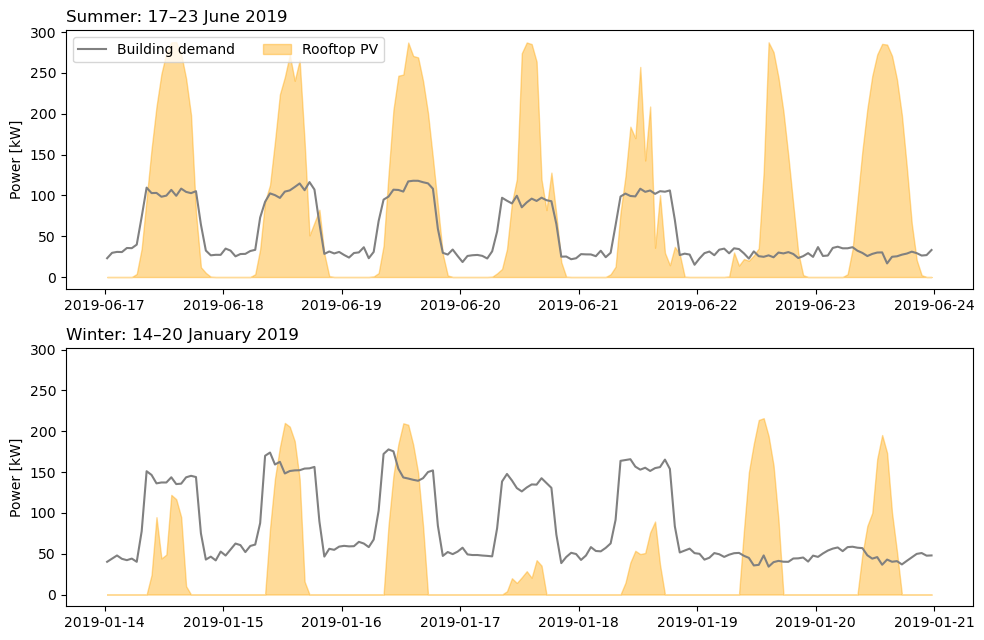

In [8]:
# Summer vs winter week (both Monday → Sunday, same y-scale)


weeks = {"Summer: 17–23 June 2019":   ("2019-06-17", "2019-06-23"),
         "Winter: 14–20 January 2019": ("2019-01-14", "2019-01-20")}

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharey=True)
for ax, (title, (start, end)) in zip(axes, weeks.items()):
    w = df.tz_convert(SITE["tz"]).loc[start:end]
    ax.plot(w.index, w["load_kw"], color="grey", lw=1.5, label="Building demand")
    ax.fill_between(w.index, 0, w["pv_kw"], color="orange", alpha=0.4, label="Rooftop PV")
    ax.set_title(title, loc="left"); ax.set_ylabel("Power [kW]")
axes[0].legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

**Interpretation**
- **Summer:** PV peaks (≈285 kW) are **2.5× the weekday demand** (≈100–115 kW). Most of the midday energy is surplus, and at the weekend, when demand drops to ≈30 kW, almost all PV is exported for a low price.
- **Winter:** demand is **higher** (≈140–175 kW on weekdays, ≈45–60 kW at night) because of heating, while PV is **lower and much more variable**: ≈210 kW on clear days (15, 16 January) and almost nothing on cloudy days (17, 18 January).
- The two sunniest winter days (19–20 January) fall on a **weekend**, when the office is empty, so the energy is wasted.

→ **Mismatch in time, not in quantity.** A battery can move summer midday surplus to the evening and buy cheap night energy in winter. To decide *how much* to buy each night, it needs to know tomorrow's PV and demand. That is the role of the forecasts in Section 2.

Why model demand instead of using real data?

Smart-meter data from a real building is private. I built a transparent model with base load, occupancy, heating, cooling and holidays, so every assumption is visible. The notebook is built so a real hourly CSV can replace it without changing the rest of the code.